In [3]:
# We import some of our usual libraries at this top level.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from scipy.stats import norm
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.model_selection import cross_val_score, train_test_split, KFold, GridSearchCV,StratifiedGroupKFold
from sklearn.preprocessing import OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, classification_report, confusion_matrix, precision_score, recall_score,roc_auc_score
import shap
from scipy.interpolate import griddata
import geopandas as gpd
import seaborn as sns

c:\Users\Adri\Desktop\modellingg\random_forest\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
import warnings

warnings.filterwarnings(
    "ignore",
    message=r".*sklearn\.utils\.parallel\.delayed.*"
)

In [5]:
###CLIMATE DATA

sun_flux = pd.read_csv(r"data_exercise2\data\Tswrfdaymean1961_1990.csv")
sun_flux_stats = pd.read_csv(r"data_exercise2\data\Tswrfdaymean1961_1990_stats.csv")

rain = pd.read_csv(r"data_exercise2\data\Predaymean1961_1990.csv")
rain_stats = pd.read_csv(r"data_exercise2\data\Predaymean1961_1990_stats.csv")

T_mean = pd.read_csv(r"data_exercise2\data\Tmpdaymean1961_1990.csv")
T_mean_stats = pd.read_csv(r"data_exercise2\data\Tmpdaymean1961_1990_stats.csv")

T_max = pd.read_csv(r"data_exercise2\data\Tmaxdaymean1961_1990.csv")
T_max_stats = pd.read_csv(r"data_exercise2\data\Tmaxdaymean1961_1990_stats.csv")

T_min = pd.read_csv(r"data_exercise2\data\Tmindaymean1961_1990.csv")
T_min_stats = pd.read_csv(r"data_exercise2\data\Tmindaymean1961_1990_stats.csv")

In [6]:
###LPJ-GUESS DATA
LPJ = pd.read_csv(r"data_exercise2\data\LPJ-GUESS_output_BERN1.csv")

In [7]:
###SOIL DATA
soil = pd.read_table(r"data_exercise2\data\soilmap.dat", sep=r"\s+")
soil.rename(axis=1,inplace=True,mapper={"lon":"Lon","lat":"Lat"})
soil.drop(columns=["cellfraction"],inplace=True)

In [8]:
###REGIONS DATA
regions = pd.read_table(r"data_exercise2\gridlist_pan_gfed_ISO3_UN_ecoregion.txt", sep=r"\s+")
## CAN GATHER REGION AND COUNTRY LON/LAT

In [9]:
###BIOME CLASSES
def format_rbg_string(rgbstring):
    """Transform a RGB string to a tuple of floats that matplotlib can understand"""
    rgbs = rgbstring.split(' ')
    rgbtup = tuple(float(rgb) for rgb in rgbs)
    return rgbtup

with open(r"data_exercise2\legend of biomes.txt", 'r') as f:
    lines = [ l.strip() for l in f.readlines()] # Remove endline characters and spaces
    
biome_names = lines[slice(0, len(lines), 2)] # Only use the biome names, not the colors
biome_names = [ ' '.join(l.split(' ')[1:]) for l in biome_names ] # Remove number in front of names
biome_rgbs = lines[slice(1, len(lines), 2)] # Filter out biome RGB colors
biome_rgbs = [format_rbg_string(rgbstr) for rgbstr in biome_rgbs]

In [10]:
all_data = [sun_flux,sun_flux_stats,rain,rain_stats,T_max,T_max_stats,T_mean,T_mean_stats,
            T_min,T_min_stats,soil,LPJ]

In [11]:
#Lattice check and sort by Longitud and Lattitude
temp = sun_flux[["Lon","Lat"]].sort_values(by=["Lon","Lat"]).reset_index(drop=True).copy()
for i,df in enumerate(all_data):
    df.sort_values(by=["Lon","Lat"],inplace=True)
    df.reset_index(drop=True,inplace=True)
    try:
        if not all(temp==df[["Lon","Lat"]].all()):
            raise ValueError(f"Lattice of dataframe {i} not equal to lattice of dataframe {i-1}")
        else:
            temp = df[["Lon","Lat"]]
    except Exception as e:
        print(i)

print("same lattices for all df")

same lattices for all df


In [12]:
def feature_extension(x,id,keys=["Lon","Lat"]):
    if "_" in x:
        return x
    else:
        return id+"_" + x if x not in keys else x

In [13]:
def season_swap_N(x):
    if "Spring" in x:
        return x.replace("Spring","Winter")
    
    if "Summer" in x:
        return x.replace("Summer","Spring")

    if "Fall" in x:
        return x.replace("Fall","Summer")

    if "Winter" in x:
        return x.replace("Winter","Fall")
    return x

def season_swap_S(x):
    if "Spring" in x:
        return x.replace("Spring","Summer")
    
    if "Summer" in x:
        return x.replace("Summer","Fall")

    if "Fall" in x:
        return x.replace("Fall","Winter")

    if "Winter" in x:
        return x.replace("Winter","Spring")
    return x

In [14]:
stats_dict = {"sun":sun_flux_stats,
            "rain":rain_stats,
            "Tmax":T_max_stats,
            "Tmean":T_mean_stats,
            "Tmin":T_min_stats}

for key,value in stats_dict.items():
    value.rename(axis=1,inplace=True,mapper=lambda x: feature_extension(x,key))



In [15]:
##Season swap
for key,value in stats_dict.items():
    N_value = value[value["Lat"]>=0.0].copy()
    N_value.rename(axis=1,inplace=True,mapper=lambda x: season_swap_N(x))

    S_value = value[value["Lat"]<0.0].copy()
    S_value.rename(axis=1,inplace=True,mapper=lambda x: season_swap_S(x))

    new_value = pd.concat([N_value,S_value],ignore_index=True)

    value.drop(value.index, inplace=True)
    value.drop(columns=value.columns, inplace=True)
    for col in new_value.columns:
        value[col] = new_value[col].values

In [16]:
first_merge = sun_flux_stats.copy()
for i,df in enumerate(list(stats_dict.values())[1:] + [soil]):
    try:
        first_merge = first_merge.merge(df,how="inner",on=["Lon","Lat"])
    except Exception as e:
        print(i)
        print(e)

first_merge = first_merge.merge(LPJ[["Lon","Lat","Biome_obs"]],on=["Lon","Lat"],how="inner")

In [17]:
regions_merge = first_merge.merge(regions[["Lon","Lat","Pan_2007","ISO3"]],on=["Lon","Lat"],how="inner")

### TRAIN BRUTE

In [25]:
def build_global_train_set(df,test_region,biome_distribution={x:100/1800 for x in np.array(range(1,19))}
    ,region_col="ISO3",biome_col="Biome_obs",possitive_class=12,negative_ratio=1.0,random_state=4):

    if test_region not in df[region_col].unique():
        raise ValueError(f"Region {test_region} not in {region_col}")
    rng = np.random.default_rng(random_state)

    # Exclude test region completely
    available = df[
        df[region_col] != test_region
    ].copy()

    # -----------------------------
    # Positives
    # -----------------------------

    positives = available[
        available[biome_col] == possitive_class
    ].copy()

    n_positive = len(positives)
    print(f"Numero de positivos:{n_positive}")
    print(f"Ratio de negativos:{negative_ratio}")

    if n_positive == 0:
        raise ValueError(
            f"No Dry Savanna outside {test_region}"
        )

    # -----------------------------
    # Negatives
    # -----------------------------

    negatives = available[
        available[biome_col] != possitive_class
    ].copy()

    n_negative = int(
        round(n_positive * negative_ratio)
    )

    # --------------------------------------------------
    # 6. Calcular número de muestras por biome
    # --------------------------------------------------
    raw_counts = {
        biome: ratio * n_negative
        for biome, ratio in biome_distribution.items()
    }

    target_counts = {
        biome: int(np.ceil(count))
        for biome, count in raw_counts.items()
    }

    sampled = []
    selected_indices = set()
    debt = 0
    for biome, n in target_counts.items():

        if n == 0:
            continue

        biome_data = negatives[
            negatives[biome_col] == biome
        ]

        if len(biome_data) < n:
            n_sample = len(biome_data)
            debt += n-len(biome_data)
        else:
            n_sample = n

        sample = biome_data.sample(n=n_sample,random_state=int(rng.integers(0, 1_000_000_000)))

        sampled.append(sample)
        selected_indices.update(sample.index)

    sampled_negatives = pd.concat(
        sampled,
        ignore_index=False
    )

    if debt > 0:
        remaining_pool = negatives[~negatives.index.isin(selected_indices)]

        if len(remaining_pool) < debt:
            raise ValueError(
                "Not enough negative observations "
                "available."
            )

        extra = remaining_pool.sample(n=debt,random_state=int(rng.integers(0, 1_000_000_000)))

        sampled_negatives = pd.concat([sampled_negatives,extra])
    # -----------------------------
    # Final train
    # -----------------------------

    train_df = pd.concat(
        [
            positives,
            sampled_negatives
        ],
        ignore_index=True
    )

    train_df = train_df.sample(
        frac=1,
        random_state=random_state
    ).reset_index(drop=True)
    
    return train_df

In [26]:
def test_creator(label,target:int=12):
    mask = regions["ISO3"].isin([label])
    coord = regions.loc[mask,["Lon","Lat"]]
    data = first_merge.merge(coord,on=["Lon","Lat"],how="inner").reset_index(drop=True)
    X_test = data.drop(columns=["Lon","Lat","Biome_obs"])
    y_test = (data["Biome_obs"] == target).astype(int)

    return X_test,y_test

In [27]:
def test(X_train,y_train,X_test,y_test,bin_class):
    score_rfc_train = accuracy_score(y_train, bin_class.predict(X_train))
    score_rfc_test = accuracy_score(y_test,bin_class.predict(X_test))
    print('Accuracy of RandomForestClassifier on train data: {:.4f}'.format(score_rfc_train))
    print('Accuracy of RandomForestClassifier on test data: {:.4f}'.format(score_rfc_test))
    print("\nClassification Report:")
    print(classification_report(y_test, bin_class.predict(X_test)))

    cm = confusion_matrix(
    y_test,
    bin_class.predict(X_test),
    labels=[1,0]
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Dry savannas","Not Dry savannas"]
    )

    disp.plot(cmap=plt.cm.Blues, colorbar=False)
    plt.show()

In [41]:
def test_global(label,positive_label=12):
    X_test,y_test = test_creator(label,target=positive_label)
    for ratio in [1,2,2.5,4,6,12]:
        global_train_set = build_global_train_set(regions_merge,label,possitive_class=positive_label,biome_distribution=real_distribution,negative_ratio=ratio)
        global_train_set["Biome_obs"]=(global_train_set["Biome_obs"]==12).astype(int)
        y_temp = global_train_set.pop("Biome_obs")
        global_train_set.drop(columns=["Lon","Lat","Pan_2007","ISO3"],inplace=True)
        X_train_gs, X_val_gs, y_train_gs, y_test_gs = train_test_split(global_train_set, y_temp, random_state=4, test_size=0.2,stratify=y_temp)
        bin_class = RandomForestClassifier(random_state=4)
        bin_class.fit(X_train_gs, y_train_gs)
        test(X_train_gs,y_train_gs,X_test,y_test,bin_class)


In [29]:
real_distribution = {2: 0.18783260968728355,
 17: 0.10989846429355814,
 9: 0.10008278285550168,
 18: 0.09672078525451504,
 16: 0.07732594482269264,
 14: 0.06698653511513575,
 5: 0.06693585173421635,
 12: 0.06154651889645385,
 15: 0.05294723860046291,
 6: 0.04642597692216722,
 8: 0.043249818384551705,
 10: 0.0287543714416043,
 1: 0.0233650386038418,
 11: 0.01735061073474008,
 3: 0.012400533864945685,
 13: 0.006200266932472842,
 7: 0.0019766518558564645}

In [48]:
1/4

0.25

Numero de positivos:2915
Ratio de negativos:1
Accuracy of RandomForestClassifier on train data: 1.0000
Accuracy of RandomForestClassifier on test data: 0.7353

Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.67      0.73        73
           1       0.68      0.81      0.74        63

    accuracy                           0.74       136
   macro avg       0.74      0.74      0.74       136
weighted avg       0.75      0.74      0.73       136



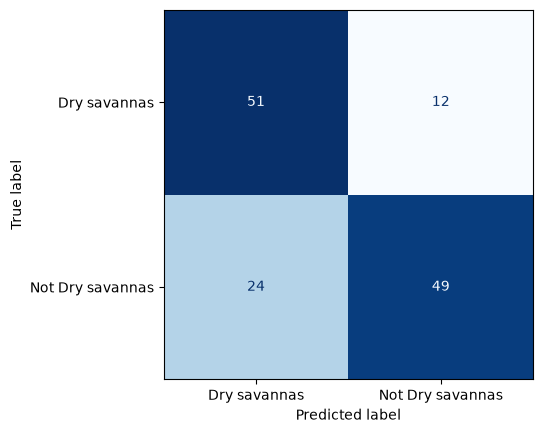

Numero de positivos:2915
Ratio de negativos:2
Accuracy of RandomForestClassifier on train data: 1.0000
Accuracy of RandomForestClassifier on test data: 0.7279

Classification Report:
              precision    recall  f1-score   support

           0       0.75      0.74      0.74        73
           1       0.70      0.71      0.71        63

    accuracy                           0.73       136
   macro avg       0.73      0.73      0.73       136
weighted avg       0.73      0.73      0.73       136



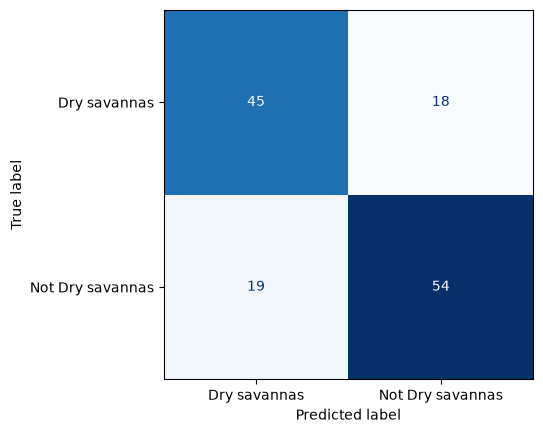

Numero de positivos:2915
Ratio de negativos:2.5
Accuracy of RandomForestClassifier on train data: 1.0000
Accuracy of RandomForestClassifier on test data: 0.7206

Classification Report:
              precision    recall  f1-score   support

           0       0.73      0.75      0.74        73
           1       0.70      0.68      0.69        63

    accuracy                           0.72       136
   macro avg       0.72      0.72      0.72       136
weighted avg       0.72      0.72      0.72       136



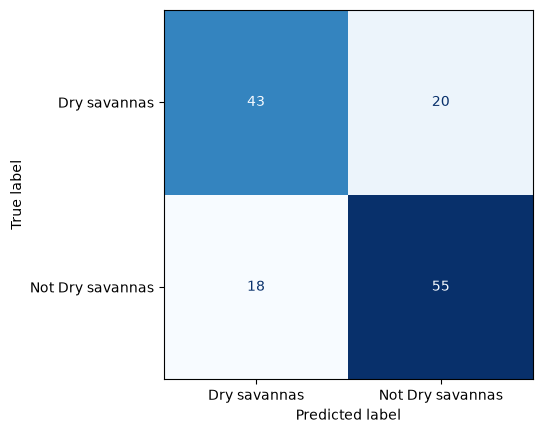

Numero de positivos:2915
Ratio de negativos:4
Accuracy of RandomForestClassifier on train data: 1.0000
Accuracy of RandomForestClassifier on test data: 0.6691

Classification Report:
              precision    recall  f1-score   support

           0       0.65      0.85      0.73        73
           1       0.72      0.46      0.56        63

    accuracy                           0.67       136
   macro avg       0.69      0.65      0.65       136
weighted avg       0.68      0.67      0.65       136



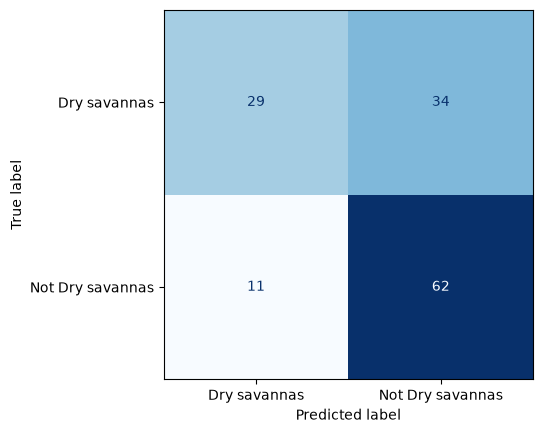

Numero de positivos:2915
Ratio de negativos:6
Accuracy of RandomForestClassifier on train data: 1.0000
Accuracy of RandomForestClassifier on test data: 0.6324

Classification Report:
              precision    recall  f1-score   support

           0       0.61      0.88      0.72        73
           1       0.71      0.35      0.47        63

    accuracy                           0.63       136
   macro avg       0.66      0.61      0.59       136
weighted avg       0.66      0.63      0.60       136



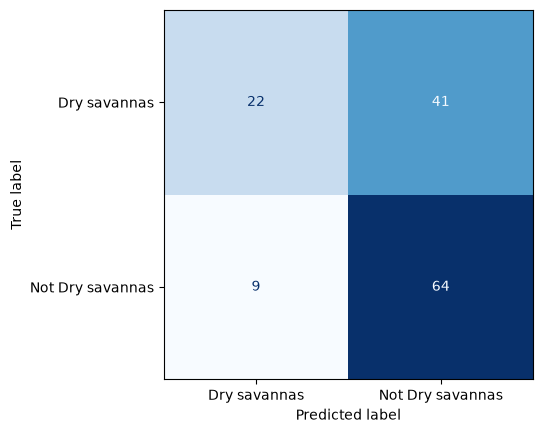

Numero de positivos:2915
Ratio de negativos:12
Accuracy of RandomForestClassifier on train data: 1.0000
Accuracy of RandomForestClassifier on test data: 0.6029

Classification Report:
              precision    recall  f1-score   support

           0       0.58      0.96      0.72        73
           1       0.80      0.19      0.31        63

    accuracy                           0.60       136
   macro avg       0.69      0.57      0.51       136
weighted avg       0.68      0.60      0.53       136



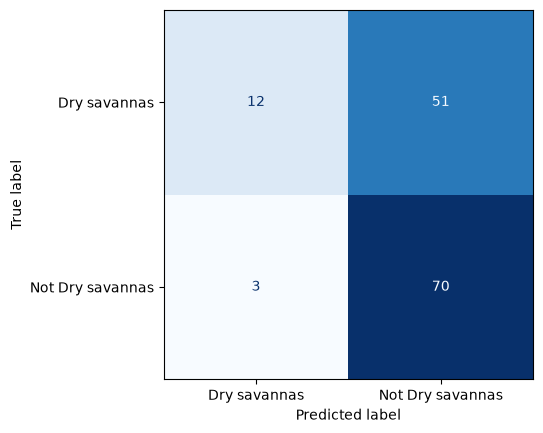

In [42]:
test_global("ZWE")

In [89]:
{key: value*2922*12 for key,value in sorted(real_distribution.items(), key=lambda x: x[0])}

{1: 819.271713605109,
 2: 6586.162626074911,
 3: 434.81231944045544,
 5: 2347.0387052085616,
 6: 1627.8804547988714,
 7: 69.30932067375107,
 8: 1516.511631835921,
 9: 3509.3026980453105,
 10: 1008.2432802284131,
 11: 608.3818148029262,
 12: 2158.067138585258,
 13: 217.40615972022772,
 14: 2348.8158672771197,
 15: 1856.5419742866316,
 16: 2711.3569292628945,
 17: 3853.4797519893227,
 18: 3391.4176141643156}

In [97]:
{k:v for k,v in sorted(first_merge["Biome_obs"].value_counts().to_dict().items(), key=lambda x: x[0])}

{1: 1383,
 2: 11118,
 3: 734,
 5: 3962,
 6: 2748,
 7: 117,
 8: 2560,
 9: 5924,
 10: 1702,
 11: 1027,
 12: 3643,
 13: 367,
 14: 3965,
 15: 3134,
 16: 4577,
 17: 6505,
 18: 5725}